# HOMEWORK 12

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW12

In this homework, you are going to use the code from ```TrafficSignsClassification``` notebook and create your own traffic sign classifier.

In [1]:
# # Silent installation or update
#
# import sys
# import apps.main as mn
#
# # Clean cache
# !"{sys.executable}" -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !"{sys.executable}" -m pip install -U "{package_name}" -q
#
# # Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-contrib-python",
#     "torch",
#     "keras",
# ]
#
# for package_name in package_array:
#     if not mn.is_package_satisfied(package_name):
#         !"{sys.executable}" -m pip install "{package_name}" -q


In [2]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input images
# hm_version = 12
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone images
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name, ".git", ".idea"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"


### Step 1

Use the data from ```data/subset_homework.pckl``` (or the ```data/subset_homework``` folder) and visualize some examples. How many images are there for each class?

In [3]:
# Load data

import pickle
import numpy as np
from pathlib import Path
import apps.reporter as rpt

# Input data
n_images = 5
file_name = "resources/data/subset_homework.pckl"

# Solution
file_path = Path(file_name)

# Load data
if file_path.exists():
    with open(file_path, "rb") as f:
        data = pickle.load(f)
else:
    raise FileNotFoundError("File doesn't exist!")

if data is None:
    raise ValueError(f'Incorrect input data "{file_name}"!')

# form classes
class_id_0 = 0
class_id_1 = 1

# get data set
images_0 = data["class_id_0"]
images_1 = data["class_id_1"]

# get lengths
len_0 = len(images_0)
len_1 = len(images_1)

# form labels
labels_0 = np.full(len_0, class_id_0)
labels_1 = np.full(len_1, class_id_1)

# analysis image
temp_img = images_0[0]

# preparing set of images for showing
first_images = []
for idx in range(n_images):
    first_images.append((labels_0[idx], images_0[idx]))
    first_images.append((labels_1[idx], images_1[idx]))

rp = rpt.Reporter()
rp.add_item(f"Class {class_id_0} samples count", str(len_0))
rp.add_item(f"Class {class_id_1} samples count", str(len_1))
rp.add_item("Total dataset samples", str(len_0 + len_1))
rp.add_item("Image: (rows, cols, channels)", str(temp_img.shape))

# Print results
rp.print_pd_report("Dataset Summary")


Attribute,Result
Class 0 samples count,2220
Class 1 samples count,2250
Total dataset samples,4470
"Image: (rows, cols, channels)","(28, 28)"


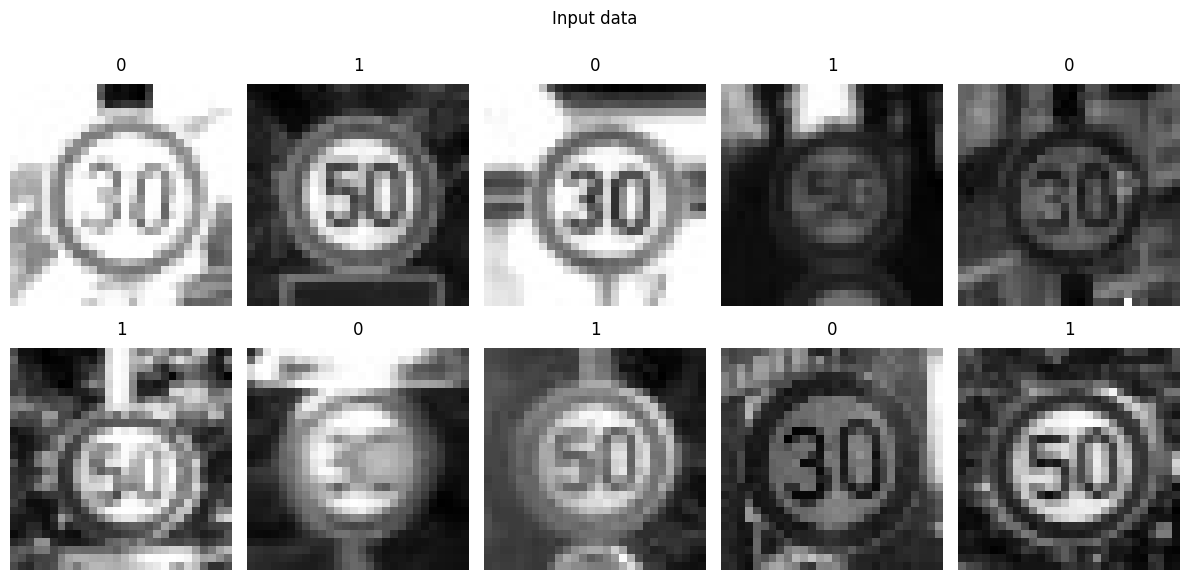

In [4]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 5
images_dict = first_images
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data", y=1.0)
plt.tight_layout()
plt.show()


### Step 2

Run the training with one single neuron (as we did in the lecture). What accuracy can you achieve?

### Step 3

Make further modifications to improve the accuracy (e.g. add more neurons, more layers, etc.). What is the maximum accuracy you can achieve?

*Note: the accuracy you compute here is measured on the same images the model was trained on. We will discuss how to evaluate a model properly in one of the next lessons.*

### Bonus question

Stack two ```Dense``` layers with ```activation="linear"``` on top of each other. Do you get a better model than with one single neuron? Why (not)? Hint: have a look at the slide about the neural network and non-linearity.

In [5]:
# Load data

import apps.main as mn

# Input data
n_images = 10

# Solution
images_dict_1 = {}

for idx in range(n_images):
    # form file name
    file_name = f"ir_{idx}.png"
    file_path = f"resources/images/{file_name}"
    # load image
    img_rgb = mn.load_image(file_path)
    # add image to dictionary
    images_dict_1[file_name] = img_rgb

# Print results


FileNotFoundError: File 'resources/images/ir_0.png' doesn't exist!

### Conclusion
1. A